In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

rng = np.random.default_rng(42)

print("NumPy version:", np.__version__)
print("Environment ready.")

NumPy version: 2.0.2
Environment ready.


In [2]:
lst = [1,2]
t = (lst, 100)
print("初始", t)

lst.append(3)
print("外部修改列表后", t)

t[0].append(4)
print("通过元组拿到列表，修改列表内部", t)

# t[0] = [999]   # 取消注释直接报错，不能修改元组保存的引用

初始 ([1, 2], 100)
外部修改列表后 ([1, 2, 3], 100)
通过元组拿到列表，修改列表内部 ([1, 2, 3, 4], 100)


In [4]:
import numpy as np

# Create the following rank 2 array with shape (3, 4)
# [[ 1  2  3  4]
#  [ 5  6  7  8]
#  [ 9 10 11 12]]
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])

# Use slicing to pull out the subarray consisting of the first 2 rows
# and columns 1 and 2; b is the following array of shape (2, 2):
# [[2 3]
#  [6 7]]
b = a[:2, 1:3]

# A slice of an array is a view into the same data, so modifying it
# will modify the original array.
print(a[0, 1])   # Prints "2"
b[0, 0] = 77     # b[0, 0] is the same piece of data as a[0, 1]
print(a[0, 1])   # Prints "77"

2
77


In [1]:
import numpy as np

print(np.__version__)

X = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12]
])

print(X)
print(X.shape)

2.4.3
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
(3, 4)


In [3]:
X = np.random.randn(2, 3, 4)
X.shape
print(X.sum(axis=0).shape)
print(X.sum(axis=1).shape)
print(X.sum(axis=2).shape)
print(X.sum(axis=-1).shape)

(3, 4)
(2, 4)
(2, 3)
(2, 3)


In [9]:
print(X)

print(X.sum(axis=0).shape)
print(X.sum(axis=1).shape)

[[1. 2. 3.]
 [4. 5. 6.]]
(3,)
(2,)


## Lab 1 — Pairwise Cosine Similarity

### Goal

Given two matrices:

- X: [N, D]
- Y: [M, D]

Compute cosine similarity between every vector in X and every vector in Y.

Output:

- similarity: [N, M]

Constraint: no Python double for-loop.

In [13]:
import numpy as np
X=np.array([
    [1.,0.,1.],
    [0.,1.,1.]
])
Y=np.array([
    [1., 1., 0.],
    [1., 0., 0.],
    [0., 1., 1.],
    [1., 1., 1.]
])

print("X.shape:",X.shape)
print("Y.shape:",Y.shape)

dot_product=X@Y.T

X_norms=np.sqrt(np.sum(X**2,axis=1))
Y_norms=np.sqrt(np.sum(Y**2,axis=1))

denominator=X_norms[:,None]*Y_norms
similarities=dot_product/denominator

print(similarities)



X.shape: (2, 3)
Y.shape: (4, 3)
[[0.5        0.70710678 0.5        0.81649658]
 [0.5        0.         1.         0.81649658]]


## Lab 2 — Stable Softmax

In [17]:
x = np.array([
    [2.0, 1.0, 0.1],
    [1.0, 3.0, 0.2]
])

print(x)
print(x.shape)

exp_x=np.exp(x)
add_exp=np.sum(exp_x,axis=1,keepdims=1)
softmax=exp_x/add_exp
print(softmax)


[[2.  1.  0.1]
 [1.  3.  0.2]]
(2, 3)
[[0.65900114 0.24243297 0.09856589]
 [0.11314284 0.8360188  0.05083836]]


减掉同一个常数，不会改变最终 softmax 的结果。

In [28]:
x = np.array([
        [1000., 1001., 1002.],
        [2000., 1998., 2001.]
    ])
def stable_softmax(x):
    exp_x=np.exp(x-x.max(axis=1,keepdims=True))
    #print(exp_x)
    add_exp=exp_x.sum(axis=1,keepdims=1)
    softmax=exp_x/add_exp
    print(softmax)
    print(softmax.sum(axis=1))
    return softmax


## Lab 3 — Cross Entropy

In [30]:
logits = np.array([
    [2.0, 1.0, 0.1, 0.2],
    [0.5, 2.5, 0.3, 0.1],
    [0.1, 0.2, 0.3, 3.0]
])

labels = np.array([0, 1, 3])
probs = stable_softmax(logits)
correct_probs=probs[np.arange(3),labels]

losses=-np.log(correct_probs)
loss=np.mean(losses)


[[0.59426642 0.2186184  0.08888361 0.09823158]
 [0.10123397 0.7480235  0.08288337 0.06785916]
 [0.04651007 0.05140158 0.05680753 0.84528082]]
[1. 1. 1.]


## Lab 4：Mini-batch Matrix Operations

In [32]:
B = 4   # batch size
D = 3   # input features
H = 2   # hidden features

X = np.array([
    [1., 2., 3.],
    [4., 5., 6.],
    [7., 8., 9.],
    [2., 3., 4.]
])

W = np.array([
    [0.1, 0.2],
    [0.3, 0.4],
    [0.5, 0.6]
])

b = np.array([0.1, 0.2])
Z=X @ W + b
H=np.maximum(Z,0)
print(H)


[[ 2.3  3. ]
 [ 5.   6.6]
 [ 7.7 10.2]
 [ 3.2  4.2]]


## Lab 5：SVD → 2D Visualization

(6, 3)
[[-2.23606504e+00  1.93693238e-03]
 [-2.45970110e+00  7.54673102e-02]
 [-2.01242899e+00 -7.15934454e-02]
 [ 2.23606504e+00 -1.93693238e-03]
 [ 2.41513441e+00  1.62453908e-01]
 [ 2.05699567e+00 -1.66327772e-01]]
(6, 2)


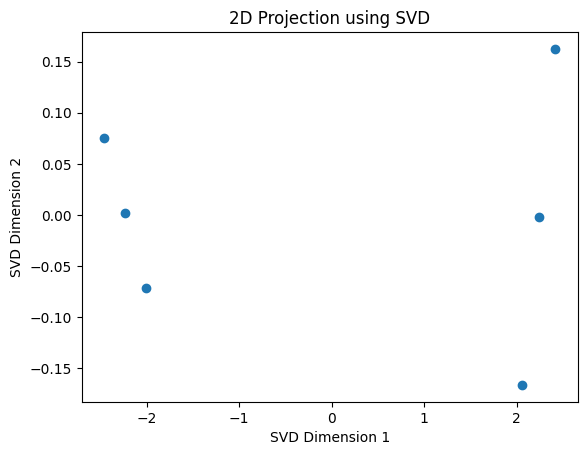

In [37]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [2., 1., 0.],
    [2.2, 1.1, 0.1],
    [1.8, 0.9, -0.1],
    [-2., -1., 0.],
    [-2.1, -1.2, 0.1],
    [-1.9, -0.8, -0.1]
])

print(X.shape)
mean = X.mean(axis=0 , keepdims=True)
X_centered = X - mean
U, S, Vt = np.linalg.svd(
    X_centered,
    full_matrices=False
)

X_2d = X_centered @ Vt[:2].T
print(X_2d)
print(X_2d.shape)
plt.scatter( X_2d[:,0], X_2d[:,1] )
plt.xlabel("SVD Dimension 1")
plt.ylabel("SVD Dimension 2")
plt.title("2D Projection using SVD")
plt.show()